# Supply Chain Data Pipeline: Northwind

An end-to-end pipeline built on the Northwind sample database (Microsoft Public License).

**Flow:** download source → extract to CSV → load into warehouse (`raw`) → transform with dbt (staging → marts) → test → analyze.

**Outputs:**
- `mart_shipping_performance`: late-delivery rate and time-to-ship by shipping company
- `mart_supplier_inventory_risk`: share of active products at or below reorder level, by supplier

**Stack:** Python (`urllib`, `duckdb`, `pandas`, `matplotlib`), SQL (DuckDB), dbt-core with dbt-duckdb.

Run from the project root. Run all cells top to bottom.

In [1]:
%pip install -q duckdb pandas matplotlib dbt-core dbt-duckdb nbformat nbclient ipykernel

Note: you may need to restart the kernel to use updated packages.


## Setup

In [2]:
import re
import subprocess
import sys
import urllib.request
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
DATA_SOURCE = ROOT / "data" / "source"
DATA_RAW = ROOT / "data" / "raw"
WAREHOUSE = ROOT / "warehouse" / "supply_chain.duckdb"
SOURCE_DB = DATA_SOURCE / "northwind_source.duckdb"
DBT_DIR = ROOT / "dbt_project"
REPORTS = ROOT / "reports"

for folder in [DATA_SOURCE, DATA_RAW, WAREHOUSE.parent, REPORTS]:
    folder.mkdir(parents=True, exist_ok=True)

RAW_TABLES = ["orders", "order_details", "products", "suppliers", "shippers"]
print("Project root:", ROOT)

Project root: /tmp/fresh3


In [3]:
# Write the dbt project files. This makes the notebook self-contained.
DBT_DIR = ROOT / "dbt_project"
dbt_files = {}
dbt_files["dbt_project.yml"] = """name: supply_chain
version: '1.0.0'
config-version: 2

profile: supply_chain

model-paths: ["models"]
test-paths: ["tests"]

models:
  supply_chain:
    staging:
      +materialized: view
    marts:
      +materialized: table
"""
dbt_files["models/marts/mart_shipping_performance.sql"] = """-- Shipping performance by carrier.
-- Only orders that have shipped are counted. Late = shipped after the required date.
with shipped as (
    select
        o.order_id,
        o.order_date,
        o.required_date,
        o.shipped_date,
        s.shipper_name
    from {{ ref('stg_orders') }} o
    join {{ ref('stg_shippers') }} s
        on o.shipper_id = s.shipper_id
    where o.shipped_date is not null
)

select
    shipper_name,
    count(*) as shipped_orders,
    cast(sum(case when shipped_date > required_date then 1 else 0 end) as integer) as late_orders,
    round(
        100.0 * sum(case when shipped_date > required_date then 1 else 0 end) / count(*),
        1
    ) as late_rate_pct,
    round(avg(date_diff('day', order_date, shipped_date)), 1) as avg_days_to_ship
from shipped
group by shipper_name
order by late_rate_pct desc
"""
dbt_files["models/marts/mart_supplier_inventory_risk.sql"] = """-- Inventory risk by supplier.
-- A product is "at risk" when units in stock are at or below its reorder level.
-- Discontinued products are excluded.
with active_products as (
    select *
    from {{ ref('stg_products') }}
    where not is_discontinued
)

select
    s.supplier_name,
    s.country,
    count(*) as active_products,
    cast(sum(case when p.units_in_stock <= p.reorder_level then 1 else 0 end) as integer) as products_at_risk,
    round(
        100.0 * sum(case when p.units_in_stock <= p.reorder_level then 1 else 0 end) / count(*),
        1
    ) as pct_products_at_risk,
    sum(p.units_in_stock) as total_units_in_stock,
    sum(p.units_on_order) as total_units_on_order
from active_products p
join {{ ref('stg_suppliers') }} s
    on p.supplier_id = s.supplier_id
group by s.supplier_name, s.country
order by pct_products_at_risk desc, products_at_risk desc
"""
dbt_files["models/marts/schema.yml"] = """version: 2

models:
  - name: mart_shipping_performance
    description: "Late-delivery rate and time-to-ship per shipping company. Shipped orders only."
    columns:
      - name: shipper_name
        tests: [unique, not_null]
      - name: late_rate_pct
        tests: [not_null]

  - name: mart_supplier_inventory_risk
    description: "Share of active products at or below reorder level, per supplier."
    columns:
      - name: supplier_name
        tests: [unique, not_null]
      - name: pct_products_at_risk
        tests: [not_null]
"""
dbt_files["models/staging/schema.yml"] = """version: 2

models:
  - name: stg_orders
    columns:
      - name: order_id
        tests: [unique, not_null]
      - name: shipper_id
        tests:
          - relationships:
              arguments:
                to: ref('stg_shippers')
                field: shipper_id

  - name: stg_order_details
    columns:
      - name: order_id
        tests:
          - not_null
          - relationships:
              arguments:
                to: ref('stg_orders')
                field: order_id
      - name: product_id
        tests:
          - relationships:
              arguments:
                to: ref('stg_products')
                field: product_id

  - name: stg_products
    columns:
      - name: product_id
        tests: [unique, not_null]
      - name: supplier_id
        tests:
          - relationships:
              arguments:
                to: ref('stg_suppliers')
                field: supplier_id

  - name: stg_suppliers
    columns:
      - name: supplier_id
        tests: [unique, not_null]

  - name: stg_shippers
    columns:
      - name: shipper_id
        tests: [unique, not_null]
"""
dbt_files["models/staging/sources.yml"] = """version: 2

sources:
  - name: raw
    description: "Northwind tables loaded as-is from the source extract (no cleaning)."
    schema: raw
    tables:
      - name: orders
      - name: order_details
      - name: products
      - name: suppliers
      - name: shippers
"""
dbt_files["models/staging/stg_order_details.sql"] = """-- One row per order line item.
select
    order_id,
    product_id,
    cast(unit_price as decimal(10, 2)) as unit_price,
    cast(quantity as integer)          as quantity,
    cast(discount as decimal(5, 2))    as discount
from {{ source('raw', 'order_details') }}
"""
dbt_files["models/staging/stg_orders.sql"] = """-- One row per sales order. Casts types and renames columns for downstream use.
select
    order_id,
    customer_id,
    cast(order_date as date)    as order_date,
    cast(required_date as date) as required_date,
    cast(shipped_date as date)  as shipped_date,
    cast(ship_via as integer)   as shipper_id,
    cast(freight as decimal(10, 2)) as freight,
    ship_country
from {{ source('raw', 'orders') }}
"""
dbt_files["models/staging/stg_products.sql"] = """-- One row per product, with current stock levels.
select
    product_id,
    product_name,
    cast(supplier_id as integer)      as supplier_id,
    cast(category_id as integer)      as category_id,
    cast(unit_price as decimal(10, 2)) as unit_price,
    cast(units_in_stock as integer)   as units_in_stock,
    cast(units_on_order as integer)   as units_on_order,
    cast(reorder_level as integer)    as reorder_level,
    cast(discontinued as integer) = 1 as is_discontinued
from {{ source('raw', 'products') }}
"""
dbt_files["models/staging/stg_shippers.sql"] = """-- One row per shipping company.
select
    cast(shipper_id as integer) as shipper_id,
    company_name                as shipper_name
from {{ source('raw', 'shippers') }}
"""
dbt_files["models/staging/stg_suppliers.sql"] = """-- One row per supplier.
select
    cast(supplier_id as integer) as supplier_id,
    company_name                 as supplier_name,
    country
from {{ source('raw', 'suppliers') }}
"""
dbt_files["profiles.yml"] = """supply_chain:
  target: dev
  outputs:
    dev:
      type: duckdb
      # dbt runs from inside dbt_project/, so this points at ../warehouse/
      path: ../warehouse/supply_chain.duckdb
      threads: 4
"""
dbt_files["tests/assert_shipped_after_ordered.sql"] = """-- Singular test: an order cannot ship before it was placed.
-- dbt fails the build if this query returns any rows.
select order_id
from {{ ref('stg_orders') }}
where shipped_date is not null
  and shipped_date < order_date
"""

for rel_path, text in dbt_files.items():
    path = DBT_DIR / rel_path
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(text, encoding="utf-8")
print("dbt project written to", DBT_DIR, "with", len(dbt_files), "files")

dbt project written to /tmp/fresh3/dbt_project with 13 files


## Step 1: Extract

Download the Northwind dump, which is a PostgreSQL script. Load it into a local "source system" database, then export the tables we need to CSV. This mimics pulling data out of an operational system.

In [4]:
DUMP_URL = "https://raw.githubusercontent.com/pthom/northwind_psql/master/northwind.sql"
LICENSE_URL = "https://raw.githubusercontent.com/pthom/northwind_psql/master/LICENSE"
dump_path = DATA_SOURCE / "northwind.sql"

if not dump_path.exists():
    urllib.request.urlretrieve(DUMP_URL, dump_path)
    urllib.request.urlretrieve(LICENSE_URL, DATA_SOURCE / "LICENSE")
print("Dump size (KB):", round(dump_path.stat().st_size / 1024))

Dump size (KB): 342


In [5]:
def clean_postgres_dump(sql: str) -> str:
    """Strip PostgreSQL-only statements so DuckDB can run the script."""
    lines = [l for l in sql.splitlines() if not re.match(r"^\s*(SET\s|SELECT pg_catalog)", l)]
    sql = "\n".join(lines).replace("'\\x'", "''")          # Postgres empty bytea literal
    sql = re.sub(r"ALTER TABLE[^;]*;", "", sql, flags=re.S)   # constraints DuckDB does not need here
    sql = re.sub(r"CREATE (UNIQUE )?INDEX[^;]*;", "", sql, flags=re.S)
    return sql

# Rebuild the source database from scratch each run
if SOURCE_DB.exists():
    SOURCE_DB.unlink()

with duckdb.connect(str(SOURCE_DB)) as source:
    source.execute(clean_postgres_dump(dump_path.read_text(encoding="utf-8")))
    for table in RAW_TABLES:
        source.execute(f"COPY {table} TO '{DATA_RAW / (table + '.csv')}' (HEADER, DELIMITER ',')")

for table in RAW_TABLES:
    print(f"{table:<15} {len(pd.read_csv(DATA_RAW / (table + '.csv'))):>6} rows exported")

orders             830 rows exported
order_details     2155 rows exported
products            77 rows exported
suppliers           29 rows exported
shippers             6 rows exported


## Step 2: Load into the warehouse (`raw` schema)

Copy the CSVs into the warehouse exactly as they are. No cleaning happens at this stage. dbt does all transformations later.

In [6]:
with duckdb.connect(str(WAREHOUSE)) as wh:
    wh.execute("CREATE SCHEMA IF NOT EXISTS raw")
    for table in RAW_TABLES:
        wh.execute(f"""
            CREATE OR REPLACE TABLE raw.{table} AS
            SELECT * FROM read_csv('{DATA_RAW / (table + '.csv')}', header=true, auto_detect=true)
        """)
    counts = wh.execute("""
        SELECT table_name, estimated_size AS row_count
        FROM duckdb_tables() WHERE schema_name = 'raw' ORDER BY table_name
    """).df()
counts

,table_name,row_count
0,order_details,2155
1,orders,830
2,products,77
3,shippers,6
4,suppliers,29


## Step 2b: Look at the source data

Northwind has 14 tables. The pipeline uses 5 of them. This section shows the full database so you can see what's in it. It reads from the source database created in Step 1.

In [7]:
with duckdb.connect(str(SOURCE_DB), read_only=True) as source:
    overview = source.execute("""
        SELECT table_name, estimated_size AS row_count
        FROM duckdb_tables() WHERE schema_name = 'main' ORDER BY table_name
    """).df()
    column_lists = {
        t: source.execute(
            f"SELECT column_name FROM information_schema.columns "
            f"WHERE table_name = '{t}' ORDER BY ordinal_position"
        ).df()["column_name"].tolist()
        for t in overview["table_name"]
    }

overview["used_by_pipeline"] = overview["table_name"].isin(RAW_TABLES)
overview

,table_name,row_count,used_by_pipeline
0,categories,8,False
1,customer_customer_demo,0,False
2,customer_demographics,0,False
3,customers,91,False
4,employee_territories,49,False
5,employees,9,False
6,order_details,2155,True
7,orders,830,True
8,products,77,True
9,region,4,False


In [8]:
for table, cols in column_lists.items():
    print(f"{table}: {', '.join(cols)}")

categories: category_id, category_name, description, picture
customer_customer_demo: customer_id, customer_type_id
customer_demographics: customer_type_id, customer_desc
customers: customer_id, company_name, contact_name, contact_title, address, city, region, postal_code, country, phone, fax
employee_territories: employee_id, territory_id
employees: employee_id, last_name, first_name, title, title_of_courtesy, birth_date, hire_date, address, city, region, postal_code, country, home_phone, extension, photo, notes, reports_to, photo_path
order_details: order_id, product_id, unit_price, quantity, discount
orders: order_id, customer_id, employee_id, order_date, required_date, shipped_date, ship_via, freight, ship_name, ship_address, ship_city, ship_region, ship_postal_code, ship_country
products: product_id, product_name, supplier_id, category_id, quantity_per_unit, unit_price, units_in_stock, units_on_order, reorder_level, discontinued
region: region_id, region_description
shippers: shipp

### Preview the five tables the pipeline uses (first 5 rows each)

In [9]:
from IPython.display import display

def preview(table, limit=5):
    # Skip binary image columns, which are not useful to read
    cols = [c for c in column_lists[table] if c not in ("photo", "picture")]
    with duckdb.connect(str(SOURCE_DB), read_only=True) as source:
        return source.execute(f"SELECT {', '.join(cols)} FROM {table} LIMIT {limit}").df()

for table in RAW_TABLES:
    print(f"--- {table}")
    display(preview(table))

--- orders


,order_id,customer_id,employee_id,order_date,required_date,shipped_date,ship_via,freight,ship_name,ship_address,ship_city,ship_region,ship_postal_code,ship_country
0,10248,VINET,5,1996-07-04,1996-08-01,1996-07-16,3,32.380001,Vins et alcools Chevalier,59 rue de l'Abbaye,Reims,NaN,51100,France
1,10249,TOMSP,6,1996-07-05,1996-08-16,1996-07-10,1,11.610000,Toms Spezialitäten,Luisenstr. 48,Münster,NaN,44087,Germany
2,10250,HANAR,4,1996-07-08,1996-08-05,1996-07-12,2,65.830002,Hanari Carnes,"Rua do Paço, 67",Rio de Janeiro,RJ,05454-876,Brazil
3,10251,VICTE,3,1996-07-08,1996-08-05,1996-07-15,1,41.340000,Victuailles en stock,"2, rue du Commerce",Lyon,NaN,69004,France
4,10252,SUPRD,4,1996-07-09,1996-08-06,1996-07-11,2,51.299999,Suprêmes délices,"Boulevard Tirou, 255",Charleroi,NaN,B-6000,Belgium


--- order_details


,order_id,product_id,unit_price,quantity,discount
0,10248,11,14.000000,12,0.0
1,10248,42,9.800000,10,0.0
2,10248,72,34.799999,5,0.0
3,10249,14,18.600000,9,0.0
4,10249,51,42.400002,40,0.0


--- products


,product_id,product_name,supplier_id,category_id,quantity_per_unit,unit_price,units_in_stock,units_on_order,reorder_level,discontinued
0,1,Chai,8,1,10 boxes x 30 bags,18.00,39,0,10,1
1,2,Chang,1,1,24 - 12 oz bottles,19.00,17,40,25,1
2,3,Aniseed Syrup,1,2,12 - 550 ml bottles,10.00,13,70,25,0
3,4,Chef Anton's Cajun Seasoning,2,2,48 - 6 oz jars,22.00,53,0,0,0
4,5,Chef Anton's Gumbo Mix,2,2,36 boxes,21.35,0,0,0,1


--- suppliers


,supplier_id,company_name,contact_name,contact_title,address,city,region,postal_code,country,phone,fax,homepage
0,1,Exotic Liquids,Charlotte Cooper,Purchasing Manager,49 Gilbert St.,London,NaN,EC1 4SD,UK,(171) 555-2222,NaN,NaN
1,2,New Orleans Cajun Delights,Shelley Burke,Order Administrator,P.O. Box 78934,New Orleans,LA,70117,USA,(100) 555-4822,NaN,#CAJUN.HTM#
2,3,Grandma Kelly's Homestead,Regina Murphy,Sales Representative,707 Oxford Rd.,Ann Arbor,MI,48104,USA,(313) 555-5735,(313) 555-3349,NaN
3,4,Tokyo Traders,Yoshi Nagase,Marketing Manager,9-8 Sekimai Musashino-shi,Tokyo,NaN,100,Japan,(03) 3555-5011,NaN,NaN
4,5,Cooperativa de Quesos 'Las Cabras',Antonio del Valle Saavedra,Export Administrator,Calle del Rosal 4,Oviedo,Asturias,33007,Spain,(98) 598 76 54,NaN,NaN


--- shippers


,shipper_id,company_name,phone
0,1,Speedy Express,(503) 555-9831
1,2,United Package,(503) 555-3199
2,3,Federal Shipping,(503) 555-9931
3,4,Alliance Shippers,1-800-222-0451
4,5,UPS,1-800-782-7892


### Preview the other tables (first 5 rows each)

In [10]:
other_tables = [t for t in column_lists if t not in RAW_TABLES]
for table in other_tables:
    print(f"--- {table}")
    display(preview(table))

--- categories


,category_id,category_name,description
0,1,Beverages,"Soft drinks, coffees, teas, beers, and ales"
1,2,Condiments,"Sweet and savory sauces, relishes, spreads, an..."
2,3,Confections,"Desserts, candies, and sweet breads"
3,4,Dairy Products,Cheeses
4,5,Grains/Cereals,"Breads, crackers, pasta, and cereal"


--- customer_customer_demo


,customer_id,customer_type_id


--- customer_demographics


,customer_type_id,customer_desc


... (8 outputs left out)

--- territories


,territory_id,territory_description,region_id
0,01581,Westboro,1
1,01730,Bedford,1
2,01833,Georgetow,1
3,02116,Boston,1
4,02139,Cambridge,1


--- us_states


,state_id,state_name,state_abbr,state_region
0,1,Alabama,AL,south
1,2,Alaska,AK,north
2,3,Arizona,AZ,west
3,4,Arkansas,AR,south
4,5,California,CA,west


## Step 3: Explore the raw data with SQL

Before modeling anything, check what the data looks like. These questions guide the marts.

In [11]:
with duckdb.connect(str(WAREHOUSE), read_only=True) as con:
    # How many orders have shipped, and how many are still open?
    status = con.execute("""
        SELECT
            CASE WHEN shipped_date IS NULL THEN 'not shipped' ELSE 'shipped' END AS status,
            COUNT(*) AS orders
        FROM raw.orders
        GROUP BY 1
    """).df()

    # Late shipments (shipped after the required date), counted from the raw data
    late = con.execute("""
        SELECT COUNT(*) AS late_orders
        FROM raw.orders
        WHERE shipped_date > required_date
    """).df()

    # Products sitting at or below their reorder level
    low_stock = con.execute("""
        SELECT COUNT(*) AS products_at_or_below_reorder
        FROM raw.products
        WHERE units_in_stock <= reorder_level AND discontinued = 0
    """).df()

print(status.to_string(index=False), "\n")
print(late.to_string(index=False), "\n")
print(low_stock.to_string(index=False))

     status  orders
    shipped     809
not shipped      21 

 late_orders
          37 

 products_at_or_below_reorder
                           17


## Step 4: Transform with dbt

dbt runs the models in `dbt_project/`:
- **Staging:** one view per raw table, with types cast and columns renamed
- **Marts:** two tables that answer the business questions
- **Tests:** uniqueness, not-null, foreign-key checks, and a singular test that an order cannot ship before it was placed

If any test fails, `dbt build` returns a non-zero exit code and the notebook stops here.

In [12]:
result = subprocess.run(
    [sys.executable, "-m", "dbt.cli.main", "build", "--profiles-dir", "."],
    cwd=DBT_DIR,
    capture_output=True,
    text=True,
)
ansi = re.compile(r"\x1b\[[0-9;]*m")
summary = [ansi.sub("", line) for line in result.stdout.splitlines() if "Done." in line or "Completed" in line or "ERROR" in line]
print("\n".join(summary))

if result.returncode != 0:
    raise RuntimeError("dbt build failed. See the output above.")

22:31:27  Completed successfully
22:31:27  Done. PASS=27 WARN=0 ERROR=0 SKIP=0 NO-OP=0 REUSED=0 TOTAL=27


## Step 5: Check the results

In [13]:
with duckdb.connect(str(WAREHOUSE), read_only=True) as con:
    shipping = con.execute("SELECT * FROM main.mart_shipping_performance").df()
    risk = con.execute("SELECT * FROM main.mart_supplier_inventory_risk").df()

    # Reconciliation: marts must agree with the raw data
    raw_shipped = con.execute("SELECT COUNT(*) FROM raw.orders WHERE shipped_date IS NOT NULL").fetchone()[0]
    raw_late = con.execute("SELECT COUNT(*) FROM raw.orders WHERE shipped_date > required_date").fetchone()[0]

assert shipping["shipped_orders"].sum() == raw_shipped, "Shipped order count does not reconcile"
assert shipping["late_orders"].sum() == raw_late, "Late order count does not reconcile"
print(f"Reconciled: {raw_shipped} shipped orders, {raw_late} late orders.")
shipping

Reconciled: 809 shipped orders, 37 late orders.


,shipper_name,shipped_orders,late_orders,late_rate_pct,avg_days_to_ship
0,United Package,315,16,5.1,9.2
1,Speedy Express,245,12,4.9,8.6
2,Federal Shipping,249,9,3.6,7.5


In [14]:
risk.head(10)

,supplier_name,country,active_products,products_at_risk,pct_products_at_risk,total_units_in_stock,total_units_on_order
0,Exotic Liquids,UK,1,1,100.0,13.0,70.0
1,Nord-Ost-Fisch Handelsgesellschaft mbH,Germany,1,1,100.0,10.0,0.0
2,Formaggi Fortini s.r.l.,Italy,3,2,66.7,23.0,110.0
3,"Specialty Biscuits, Ltd.",UK,4,2,50.0,74.0,50.0
4,Lyngbysild,Denmark,2,1,50.0,100.0,70.0
5,Cooperativa de Quesos 'Las Cabras',Spain,2,1,50.0,108.0,30.0
6,Tokyo Traders,Japan,2,1,50.0,35.0,20.0
7,Leka Trading,Singapore,2,1,50.0,44.0,10.0
8,Zaanse Snoepfabriek,Netherlands,2,1,50.0,51.0,70.0
9,Pasta Buttini s.r.l.,Italy,2,1,50.0,57.0,10.0


## Step 6: Charts

Suppliers excluded from the ranking (fewer than 3 active products): 16


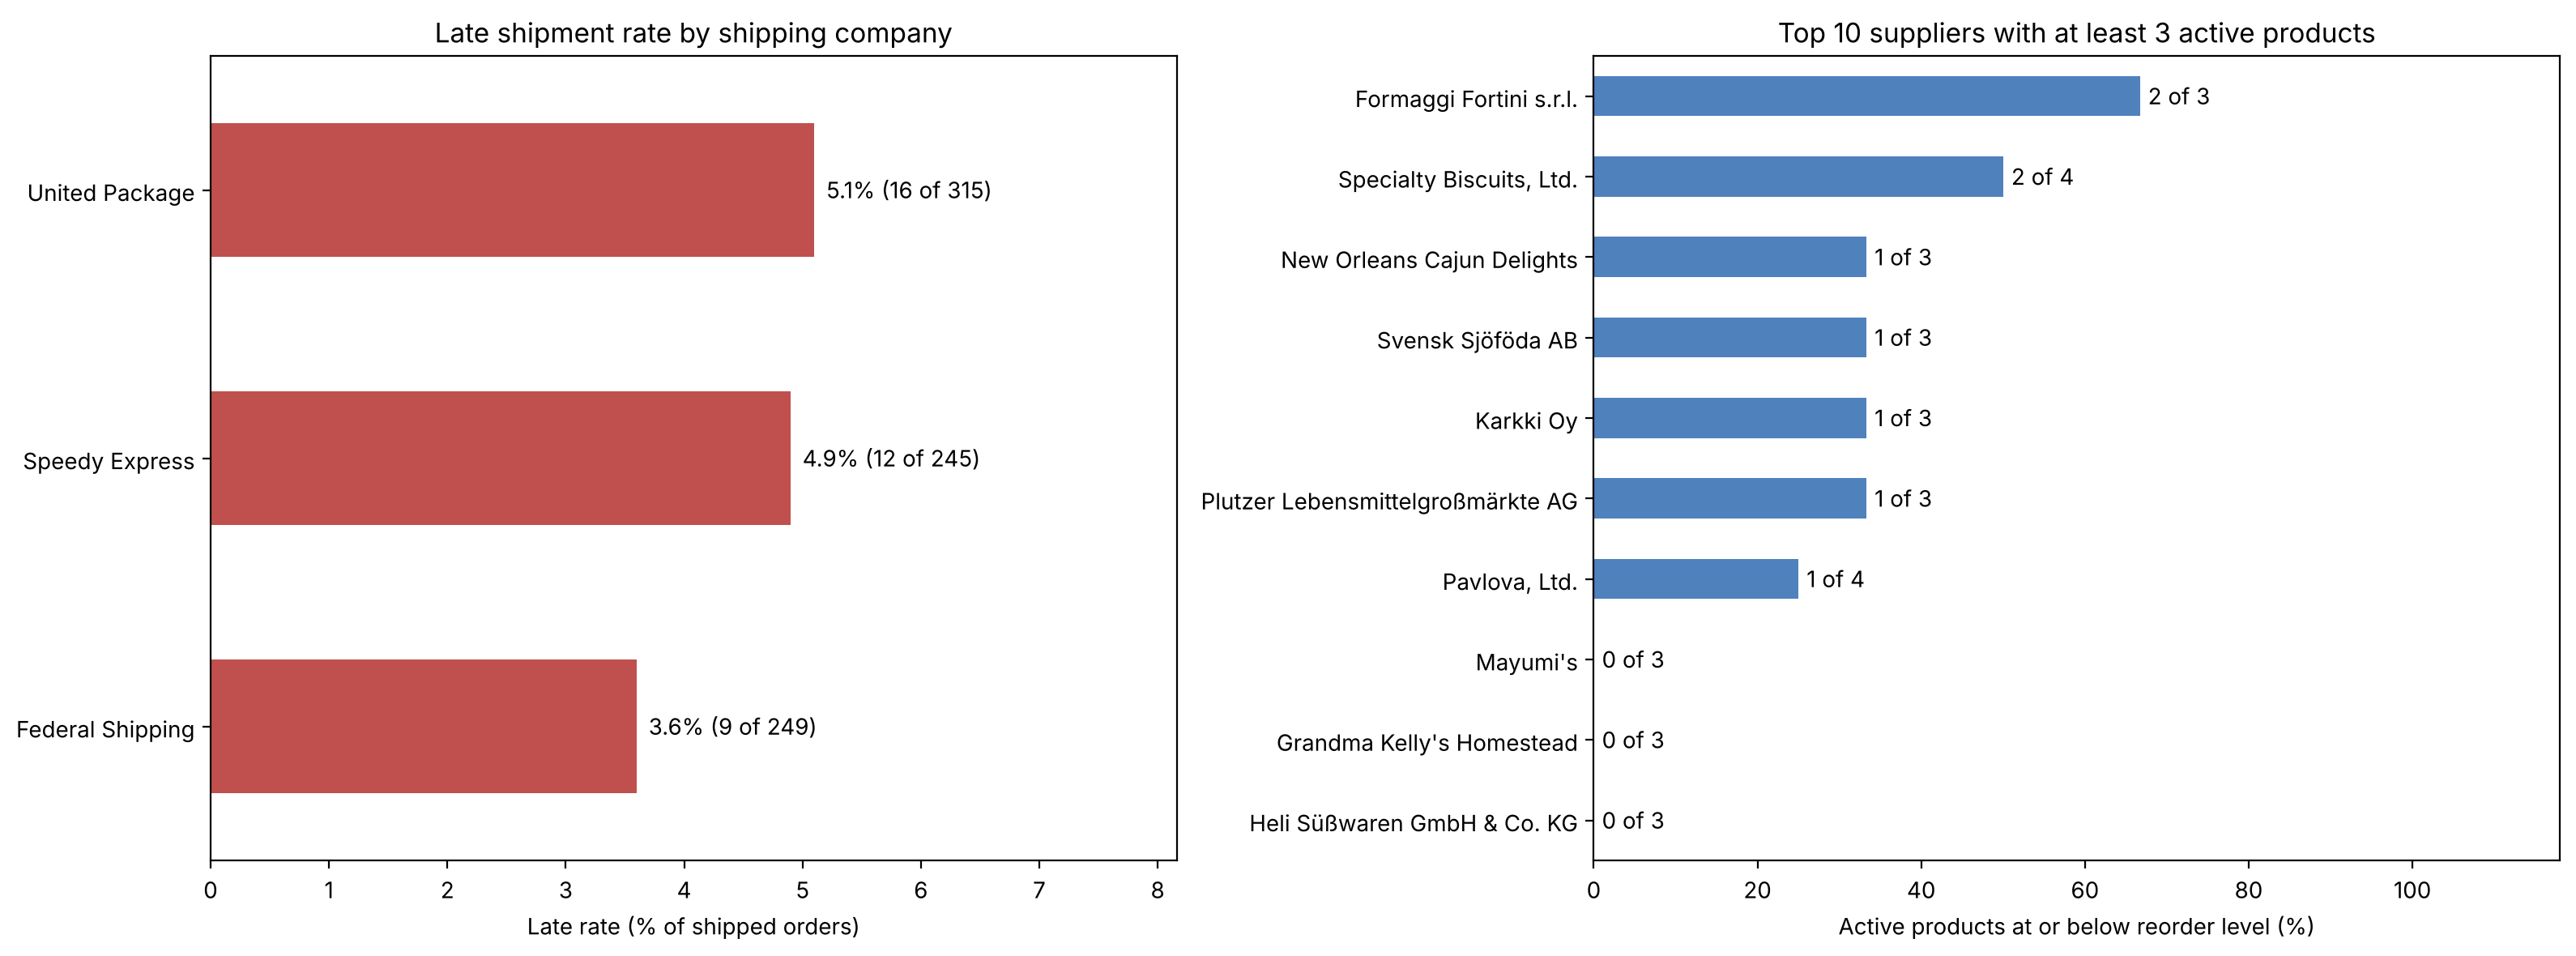

Saved: /tmp/fresh3/reports/supply_chain_dashboard.png


In [15]:
MIN_PRODUCTS = 3  # suppliers with fewer active products are too small to rank fairly
too_small = int((risk["active_products"] < MIN_PRODUCTS).sum())
print(f"Suppliers excluded from the ranking (fewer than {MIN_PRODUCTS} active products): {too_small}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: late rate by shipper, labeled with the counts behind each rate
shipping_plot = shipping.sort_values("late_rate_pct")
bars = shipping_plot.plot.barh(x="shipper_name", y="late_rate_pct", ax=axes[0], legend=False, color="#c0504d")
for bar, (_, row) in zip(bars.patches, shipping_plot.iterrows()):
    axes[0].text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
                 f"{row.late_rate_pct}% ({row.late_orders} of {row.shipped_orders})", va="center")
axes[0].set_xlim(0, shipping_plot["late_rate_pct"].max() * 1.6)
axes[0].set_title("Late shipment rate by shipping company")
axes[0].set_xlabel("Late rate (% of shipped orders)")
axes[0].set_ylabel("")

# Right: suppliers with enough products to rank, labeled with the counts behind each share
ranked = risk[risk["active_products"] >= MIN_PRODUCTS].head(10).sort_values("pct_products_at_risk")
bars2 = ranked.plot.barh(x="supplier_name", y="pct_products_at_risk", ax=axes[1], legend=False, color="#4f81bd")
for bar, (_, row) in zip(bars2.patches, ranked.iterrows()):
    axes[1].text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
                 f"{row.products_at_risk} of {row.active_products}", va="center")
axes[1].set_xlim(0, 118)
axes[1].set_title(f"Top 10 suppliers with at least {MIN_PRODUCTS} active products")
axes[1].set_xlabel("Active products at or below reorder level (%)")
axes[1].set_ylabel("")

plt.tight_layout()
fig.savefig(REPORTS / "supply_chain_dashboard.png", dpi=150)
plt.show()
print("Saved:", REPORTS / "supply_chain_dashboard.png")

## Step 7: See what is in the warehouse

The warehouse is a single file. This cell opens it and lists every table and view, with the number of rows in each.

In [16]:
rows = []
with duckdb.connect(str(WAREHOUSE), read_only=True) as wh:
    objects = wh.execute("""
        SELECT schema_name, table_name, 'table' AS kind FROM duckdb_tables()
        UNION ALL
        SELECT schema_name, view_name, 'view' FROM duckdb_views()
        WHERE NOT internal AND schema_name IN ('raw', 'main')
    """).fetchall()
    for schema, name, kind in objects:
        count = wh.execute(f'SELECT COUNT(*) FROM "{schema}"."{name}"').fetchone()[0]
        rows.append({"object": f"{schema}.{name}", "type": kind, "rows": count})

warehouse_contents = pd.DataFrame(rows).sort_values(["type", "object"]).reset_index(drop=True)
warehouse_contents

,object,type,rows
0,main.mart_shipping_performance,table,3
1,main.mart_supplier_inventory_risk,table,28
2,raw.order_details,table,2155
3,raw.orders,table,830
4,raw.products,table,77
5,raw.shippers,table,6
6,raw.suppliers,table,29
7,main.stg_order_details,view,2155
8,main.stg_orders,view,830
9,main.stg_products,view,77


### Preview the two marts

In [17]:
with duckdb.connect(str(WAREHOUSE), read_only=True) as wh:
    print("main.mart_shipping_performance")
    display(wh.execute("SELECT * FROM main.mart_shipping_performance").df())
    print("main.mart_supplier_inventory_risk (first 10 rows)")
    display(wh.execute("SELECT * FROM main.mart_supplier_inventory_risk LIMIT 10").df())

main.mart_shipping_performance


,shipper_name,shipped_orders,late_orders,late_rate_pct,avg_days_to_ship
0,United Package,315,16,5.1,9.2
1,Speedy Express,245,12,4.9,8.6
2,Federal Shipping,249,9,3.6,7.5


main.mart_supplier_inventory_risk (first 10 rows)


,supplier_name,country,active_products,products_at_risk,pct_products_at_risk,total_units_in_stock,total_units_on_order
0,Exotic Liquids,UK,1,1,100.0,13.0,70.0
1,Nord-Ost-Fisch Handelsgesellschaft mbH,Germany,1,1,100.0,10.0,0.0
2,Formaggi Fortini s.r.l.,Italy,3,2,66.7,23.0,110.0
3,"Specialty Biscuits, Ltd.",UK,4,2,50.0,74.0,50.0
4,Lyngbysild,Denmark,2,1,50.0,100.0,70.0
5,Cooperativa de Quesos 'Las Cabras',Spain,2,1,50.0,108.0,30.0
6,Tokyo Traders,Japan,2,1,50.0,35.0,20.0
7,Leka Trading,Singapore,2,1,50.0,44.0,10.0
8,Zaanse Snoepfabriek,Netherlands,2,1,50.0,51.0,70.0
9,Pasta Buttini s.r.l.,Italy,2,1,50.0,57.0,10.0


## Step 8: Animate the pipeline for stakeholders

This cell builds a short animation. A single order's flow is shown as a dot moving from the source system to the marts, with the order counts at each stage. The numbers come from the warehouse, so the animation changes if the data changes.

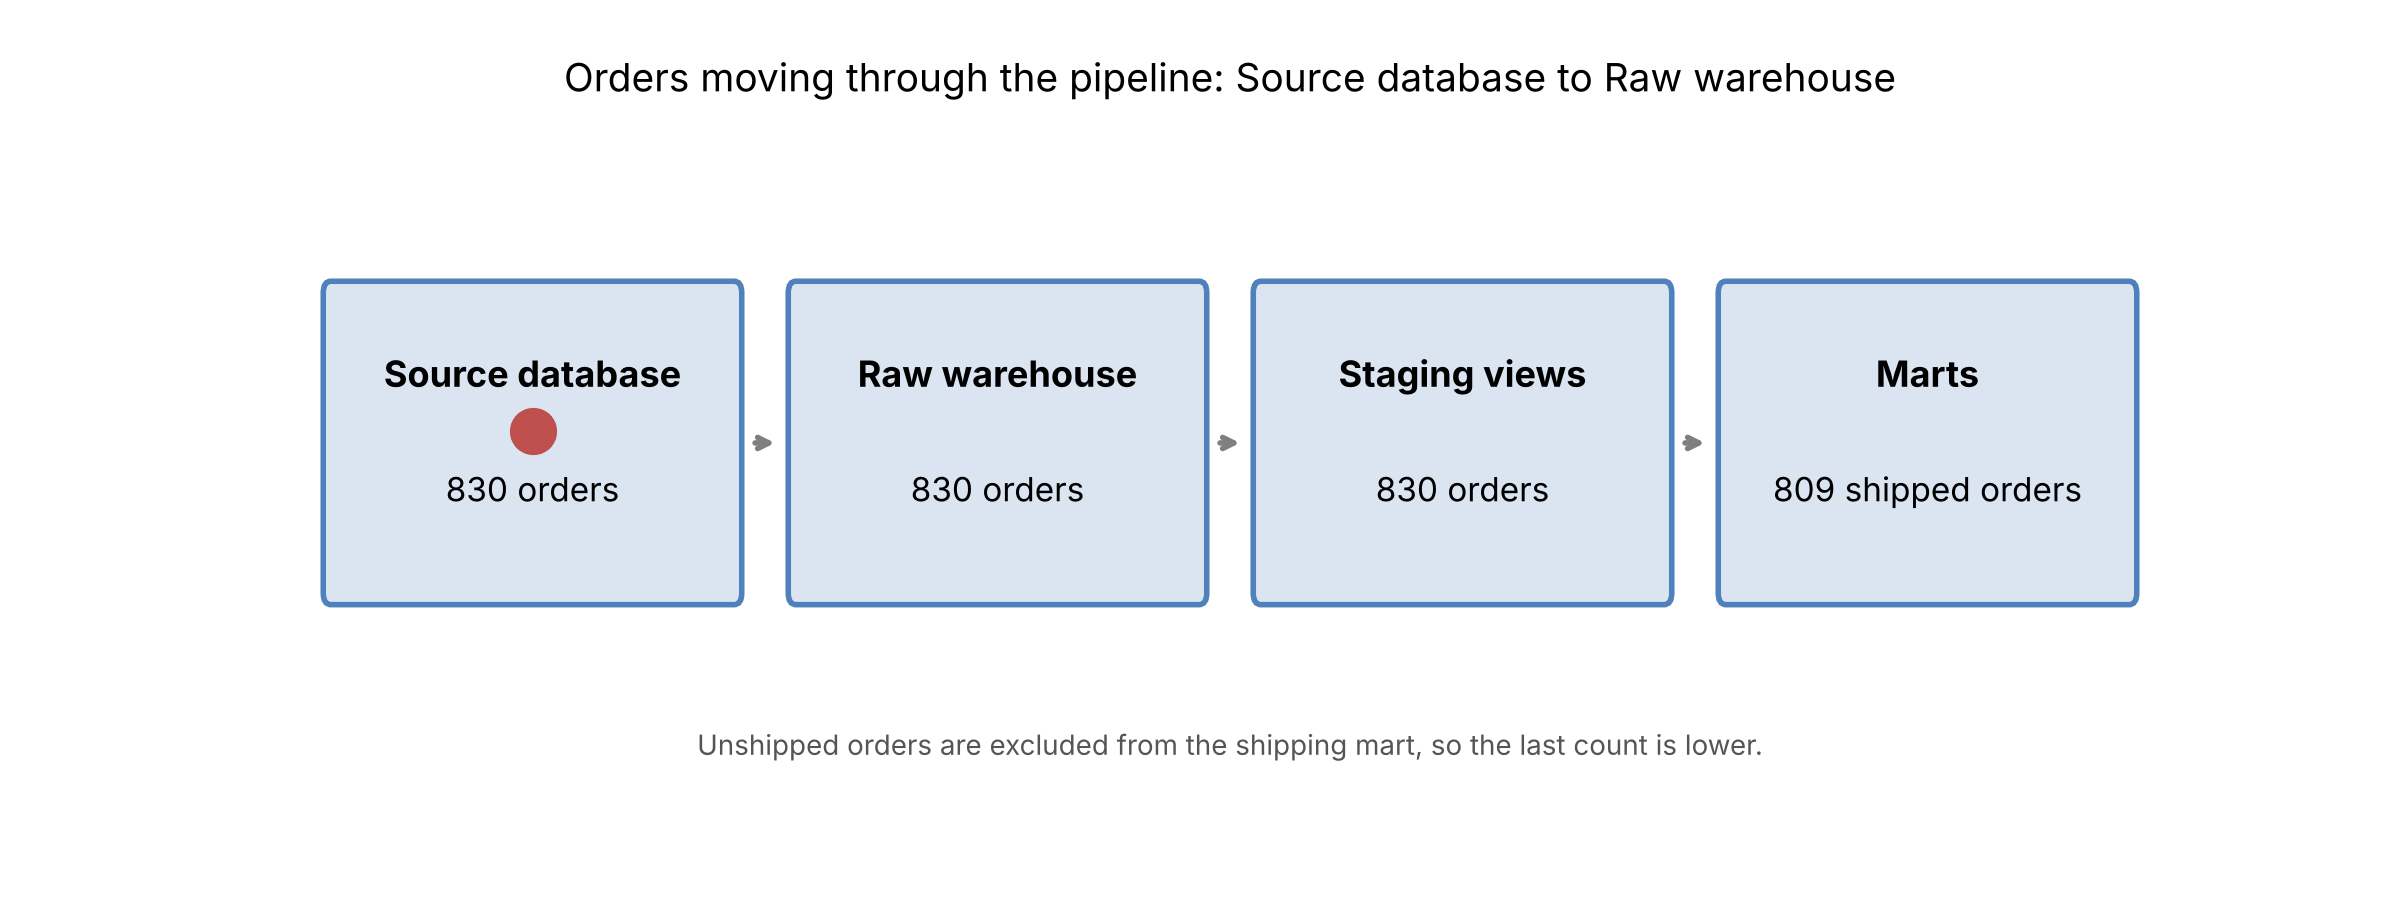

Saved: /tmp/fresh3/reports/pipeline_flow.gif


In [18]:
import matplotlib.animation as animation
import matplotlib.patches as patches

with duckdb.connect(str(SOURCE_DB), read_only=True) as s:
    source_orders = s.execute("SELECT COUNT(*) FROM orders").fetchone()[0]
with duckdb.connect(str(WAREHOUSE), read_only=True) as wh:
    raw_orders = wh.execute("SELECT COUNT(*) FROM raw.orders").fetchone()[0]
    staged_orders = wh.execute("SELECT COUNT(*) FROM main.stg_orders").fetchone()[0]
shipped_in_mart = int(shipping["shipped_orders"].sum())

stage_info = [
    ("Source database", f"{source_orders} orders"),
    ("Raw warehouse", f"{raw_orders} orders"),
    ("Staging views", f"{staged_orders} orders"),
    ("Marts", f"{shipped_in_mart} shipped orders"),
]
centers = [1.5, 4.5, 7.5, 10.5]
box_w, box_h = 2.6, 1.3
FRAMES_PER_HOP = 20
HOLD_FRAMES = 25
total_frames = FRAMES_PER_HOP * (len(centers) - 1) + HOLD_FRAMES

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.set_xlim(0, 12)
ax.set_ylim(-0.6, 2.4)
ax.axis("off")

for x, (name, label) in zip(centers, stage_info):
    ax.add_patch(patches.FancyBboxPatch(
        (x - box_w / 2, 0.3), box_w, box_h, boxstyle="round,pad=0.05",
        facecolor="#dbe5f1", edgecolor="#4f81bd", linewidth=2))
    ax.text(x, 1.25, name, ha="center", va="center", fontsize=13, weight="bold")
    ax.text(x, 0.75, label, ha="center", va="center", fontsize=12)

for left, right in zip(centers[:-1], centers[1:]):
    ax.annotate("", xy=(right - box_w / 2 - 0.1, 0.95), xytext=(left + box_w / 2 + 0.1, 0.95),
                arrowprops=dict(arrowstyle="->", color="#7f7f7f", lw=2))

dot, = ax.plot([], [], "o", color="#c0504d", markersize=16)
title = ax.set_title("", fontsize=14)
ax.text(6, -0.4, "Unshipped orders are excluded from the shipping mart, so the last count is lower.",
        ha="center", fontsize=10, color="#555555")

def update(frame):
    if frame >= FRAMES_PER_HOP * (len(centers) - 1):
        x = centers[-1]
        hop = len(centers) - 2
    else:
        hop = frame // FRAMES_PER_HOP
        t = (frame % FRAMES_PER_HOP) / FRAMES_PER_HOP
        x = centers[hop] + (centers[hop + 1] - centers[hop]) * t
    dot.set_data([x], [1.0])
    title.set_text(f"Orders moving through the pipeline: {stage_info[hop][0]} to {stage_info[hop + 1][0]}")
    return dot, title

anim = animation.FuncAnimation(fig, update, frames=total_frames, interval=80)
anim.save(REPORTS / "pipeline_flow.gif", writer="pillow", fps=12)
plt.close(fig)

from IPython.display import Image, display
display(Image(filename=str(REPORTS / "pipeline_flow.gif")))
print("Saved:", REPORTS / "pipeline_flow.gif")

## Done

- Warehouse: `warehouse/supply_chain.duckdb`
- Marts: `main.mart_shipping_performance`, `main.mart_supplier_inventory_risk`
- Chart: `reports/supply_chain_dashboard.png`

Rerun the whole notebook to rebuild everything from the source dump.